In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
epsilon = 1e-16
R = np.linspace(0 + epsilon, 15, 10000)
theta_ = np.array([0, 15, 30, 45, 60, 75, 90, 105, 120, 135, 150, 165])
theta = (theta_*np.pi/180 + 0*np.pi)

""" Definimos las constantes """
    
N = 100                 # Define la forma del brazo. Se hace que N >> 1 en los modelos?
Rs = 2.5                 # Distancia galactocéntrica en la que el patrón espiral comienza
i0 = 15.5*np.pi/180       # Pitch angle
A = 950/100             # Amplitud en km^2 s^-2 kpc^-1. Multiplicado por 1/100 para que coincidan las unidades
epsilon_s = 1/2.5        # Inverso de la longitud de escala radial

In [3]:
def magnitude(acx, acy): 
    mag = np.sqrt(acx**2 + acy**2)
    return mag

def accTWA_R(x, y, z): 
    
    R = np.sqrt(x**2 + y**2)
    phi = np.tan(y/x)
    
    Theta = 2*phi - 2/(N*np.tan(i0))*np.log(1 + (R/Rs)**N)
    
    F = A*np.exp(-epsilon_s*R)*(np.cos(Theta)*(1-epsilon_s*R) - R*np.sin(Theta)*(2/np.tan(i0)*(R**(N-1))/(Rs**N + R**N)))

    return F

def accTWA(x,y,z):
    R = np.sqrt(x**2 + y**2)
    
    Theta = 2/(N*np.tan(i0))*np.log(1+(R/Rs)**N)
    
    cos_cx = 2 - epsilon_s*(x**2 - y**2)/R - (x**2 - y**2)/R**2 + 4*x*y*R**(N-2)/(np.tan(i0)*(Rs**N + R**N))
    sin_cx = y - epsilon_s*(x**2)*y/R - (x**2 - y**2)*x*R**(N-2)/(np.tan(i0)*(Rs**N + R**N)) - (y*x**2)/(R**2)
    acx = (A/R)*np.exp(-epsilon_s*R)*(x*np.cos(Theta)*cos_cx + 2*np.sin(Theta)*sin_cx)

    cos_cy = -2 - epsilon_s*(x**2 - y**2)/R - (x**2 - y**2)/R**2 + 4*x*y*R**(N-2)/(np.tan(i0)*(Rs**N + R**N))
    sin_cy = x - epsilon_s*x*y**2/R - (x**2 - y**2)*y*R**(N-2)/(np.tan(i0)*(Rs**N + R**N)) - x*y**2/R**2
    acy = (A/R)*np.exp(-epsilon_s*R)*(y*np.cos(Theta)*cos_cy + 2*np.sin(Theta)*sin_cy)

    return acx, acy

def radial_force(x, y, z, acx, acy, acz):
    R = np.sqrt(x**2 + y**2 + z**2)
    Fr = -(1/R)*(x*acx + y*acy + z*acz)
    return Fr

def phiTWA(x,y,z):

    R = np.sqrt(x**2 + y**2)
    phi_cos = -A*R*np.exp(-epsilon_s*R)*np.cos(2*np.arctan(y/x) - 2/(N*np.tan(i0))*np.log(1+(R/Rs)**N))
    
    return phi_cos

def phiAS(v):
    m1, b1 = 606., 0.3873
    m2, a2, b2 = 3690., 5.3178, .25
    m3, a3 = 4615., 12.0

    x, y, z = v[0], v[1], v[2]
    R = np.sqrt(x**2 + y**2 + z**2)
    truncation = 100
    R_  = max(R, 1e-6)
    R_ = np.minimum(R_, truncation)
    
    omega = np.sqrt(x**2 + y**2)

    M_R = m3*(R_/a3)**(2.02)/(1 + (R_/a3)**(1.02))
    term1 = -(1.02)/(1 + (100/a3)**(1.02)) + np.log(1 + (100/a3)**(1.02))
    term2 = -(1.02)/(1 + (R_/a3)**(1.02)) + np.log(1 + (R_/a3)**(1.02))
        
    phi1 = -m1/ np.sqrt(R**2 +b1**2)
    phi2 = -m2 / np.sqrt(omega**2 + (a2 + np.sqrt(z**2 + b2**2))**2)
    phi3 = -M_R/R_ - (m3/(1.02 * a3)) * (term1 - term2)

    phi = phi1 + phi2 + phi3
    return phi

"""
Cálculo de las contribuciones de cada uno de los 
componentes del potencial galáctico en la aceleración.
"""

M3 = 4615.
a3 = 12.

def halo(x, R):
    a = -(1.02*M3*(x/R))*((R/a3)**2.02)
    b = R*(1+(R/a3)**1.02)
        
    c = M3 * x * ((R/a3)**(1.02)) / (a3 * R**2)
    d = 1 + (R/a3)**(1.02)
        
    halo = c / d
    return halo

def accAS(v): 
    x, y, z = v[0], v[1], v[2]
    R = np.sqrt(x**2 + y**2 + z**2) # kpc units
    truncation = 100
    R = np.minimum(R, truncation)
    R  = max(R, 1e-6)
    
    # Central mass
    M1 = 606.
    b1 = 0.3873
    
    dphi_x1 =  M1*x/(x**2 + y**2 + z**2 + b1**2)**(3/2)
    dphi_y1 =  M1*y/(x**2 + y**2 + z**2 + b1**2)**(3/2)
    dphi_z1 =  M1*z/(x**2 + y**2 + z**2 + b1**2)**(3/2) 
    
    # Disk component
    M2 = 3690.
    a2 = 5.3178
    b2 = 0.25
    
    dphi_x2 = M2*x / (x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2)**(3/2)
    dphi_y2 = M2*y / (x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2)**(3/2)
    dphi_z2 = M2*z*(a2 + np.sqrt(z**2 + b2**2))/(np.sqrt(z**2 + b2**2)*(np.sqrt(x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2))**3)
    
    # Halo
    
    dphi_x3 = halo(x, R)
    dphi_y3 = halo(y, R)
    dphi_z3 = halo(z, R)
    
    dphi_x = dphi_x1 + dphi_x2 + dphi_x3
    dphi_y = dphi_y1 + dphi_y2 + dphi_y3
    dphi_z = dphi_z1 + dphi_z2 + dphi_z3

    acx, acy, acz = -dphi_x, -dphi_y, -dphi_z
    return np.array([acx, acy, acz])

In [4]:
sun = np.array([8.5, 0, 0])
phi_sun = phiAS(sun)
acc_sunx, acc_suny, acc_sunz = accAS(sun)
acc_sun = radial_force(sun[0], sun[1], sun[2], acc_sunx, acc_suny, acc_sunz) 

forces = {}
radial_forces = {}
azimuthal_forces = {}
phi = {}

for i in range(len(theta)):

    x = R * np.cos(theta[i])
    y = R * np.sin(theta[i])
    z = np.zeros_like(R)

    phi_ = phiTWA(x, y, z)/np.absolute(phi_sun)*1e2
    fTWAx, fTWAy = accTWA(x, y, z)
    FrTWA = radial_force(x, y, z, fTWAx, fTWAy, 0)/acc_sun

    radial_forces[str(theta_[i])] = FrTWA
    phi[str(theta_[i])] = phi_

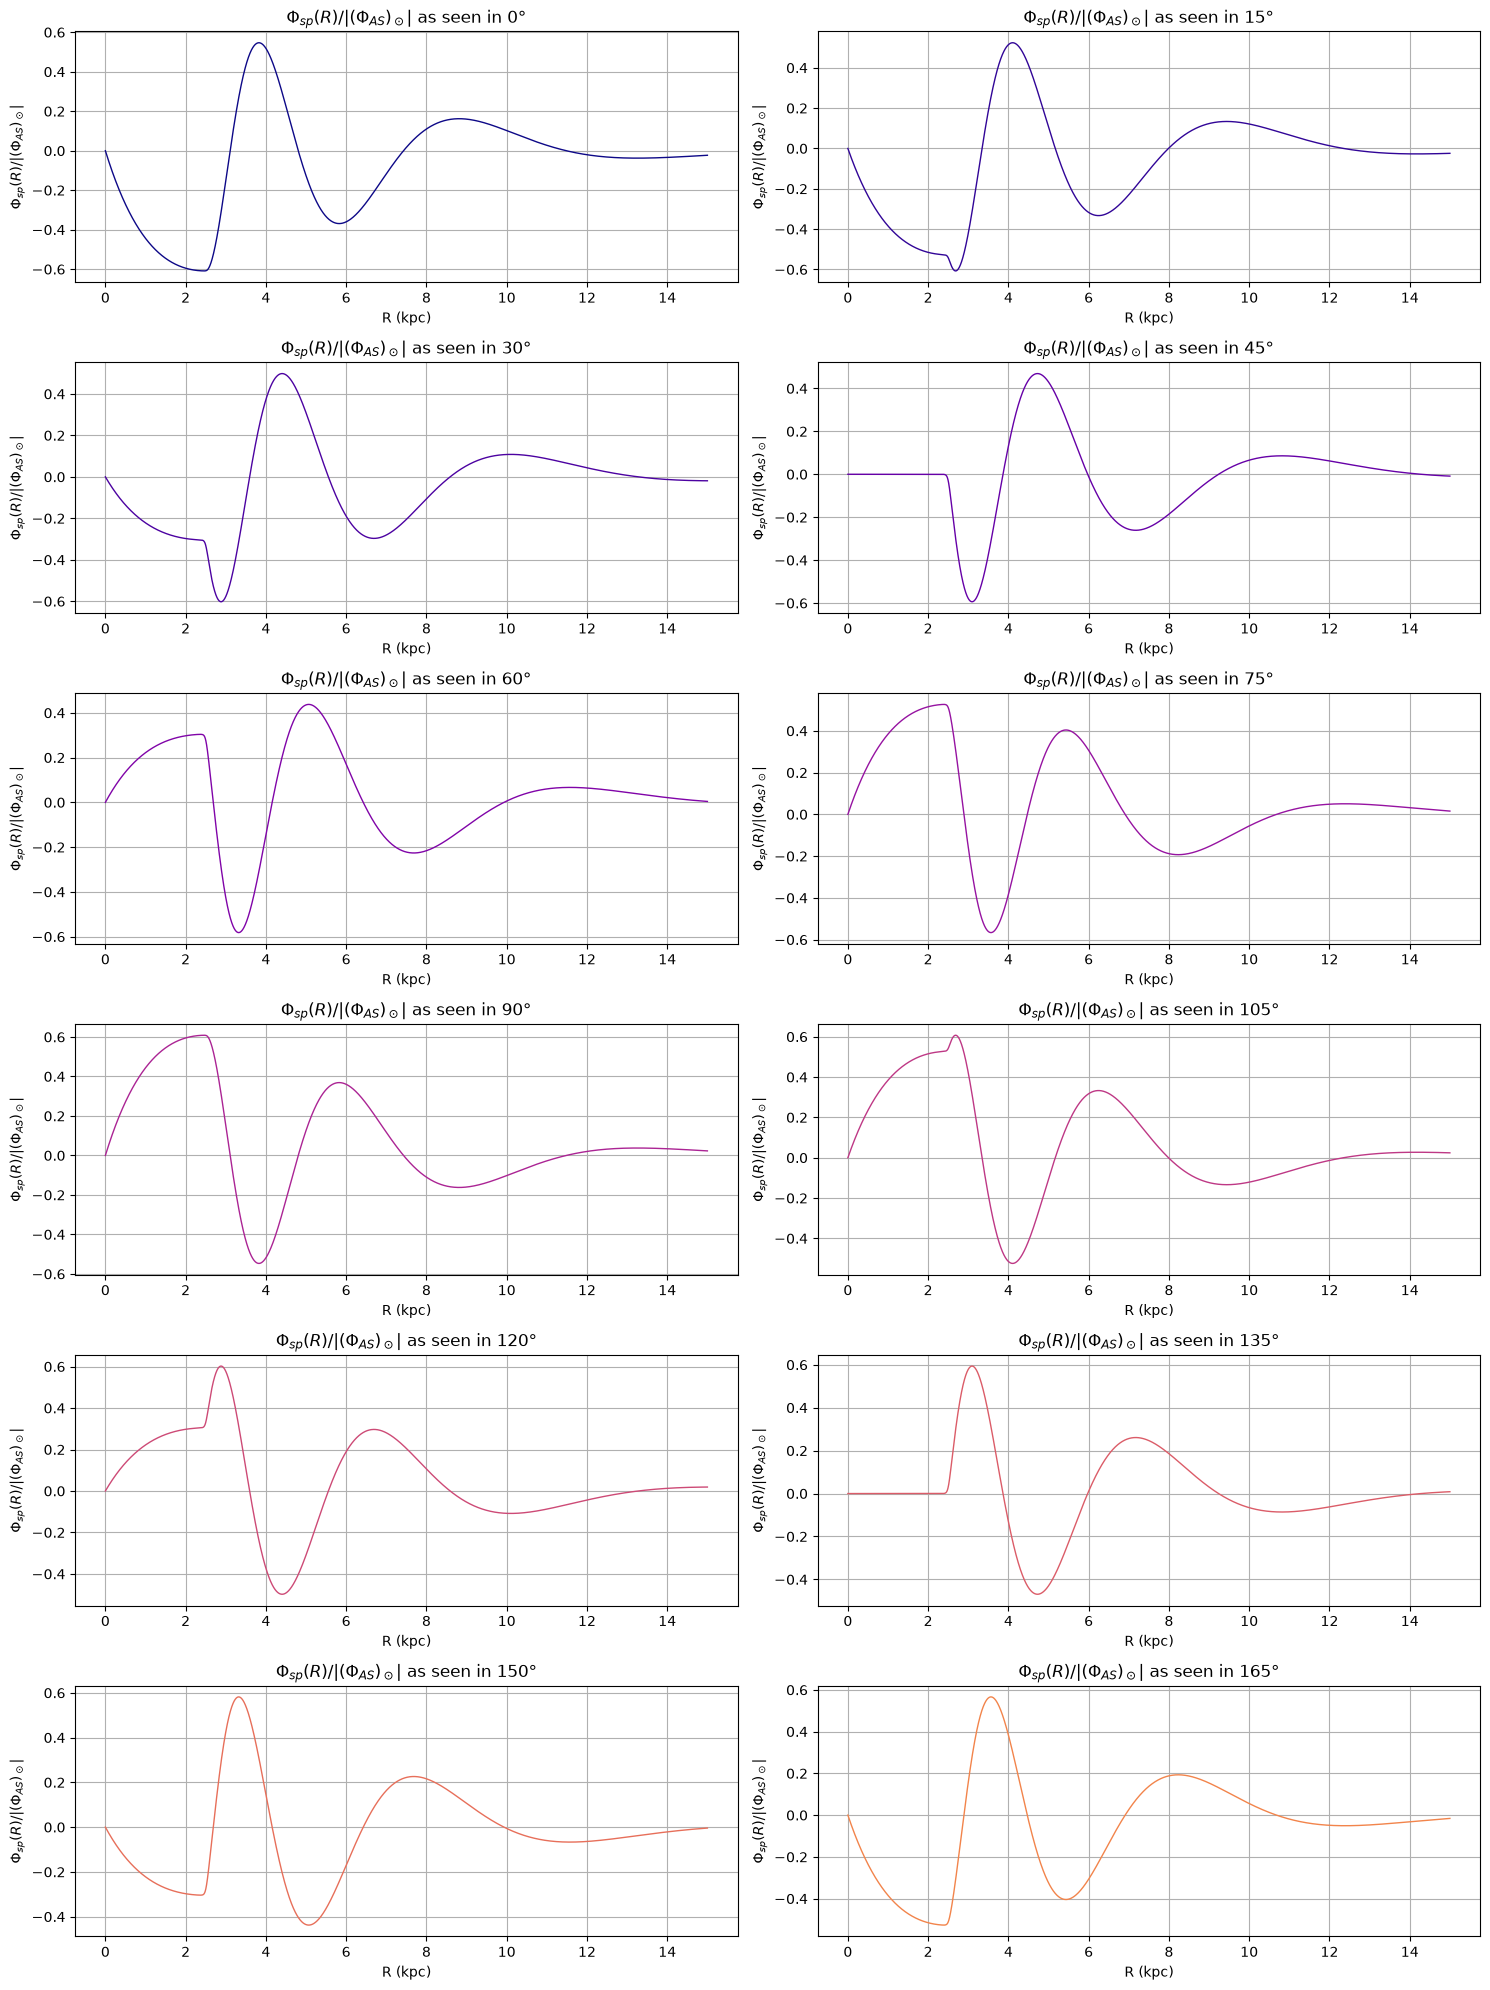

In [5]:
colors = plt.cm.plasma(np.linspace(0, 0.7, len(theta)))

fig, ax = plt.subplots(6, 2, figsize = (15, 20))

for i in range(6):
    ax[i, 0].plot(R, phi[str(theta_[2*i])], lw = 1, color = colors[2*i])
    ax[i, 0].set_xlabel(r"R (kpc)")
    ax[i, 0].set_ylabel(r"$\Phi_{sp}(R) / |(\Phi_{AS})_\odot|$")
    ax[i, 0].set_title(r"$\Phi_{sp}(R) / |(\Phi_{AS})_\odot|$" + f" as seen in {15*2*i}°")
    ax[i, 0].grid()

    ax[i, 1].plot(R, phi[str(theta_[2*i+1])], lw = 1, color = colors[2*i+1])
    ax[i, 1].set_xlabel(r"R (kpc)")
    ax[i, 1].set_ylabel(r"$\Phi_{sp}(R) / |(\Phi_{AS})_\odot|$")
    ax[i, 1].set_title(r"$\Phi_{sp}(R) / |(\Phi_{AS})_\odot|$" + f" as seen in {15*(2*i+1)}°")
    ax[i, 1].grid()
    
plt.tight_layout()
plt.show()

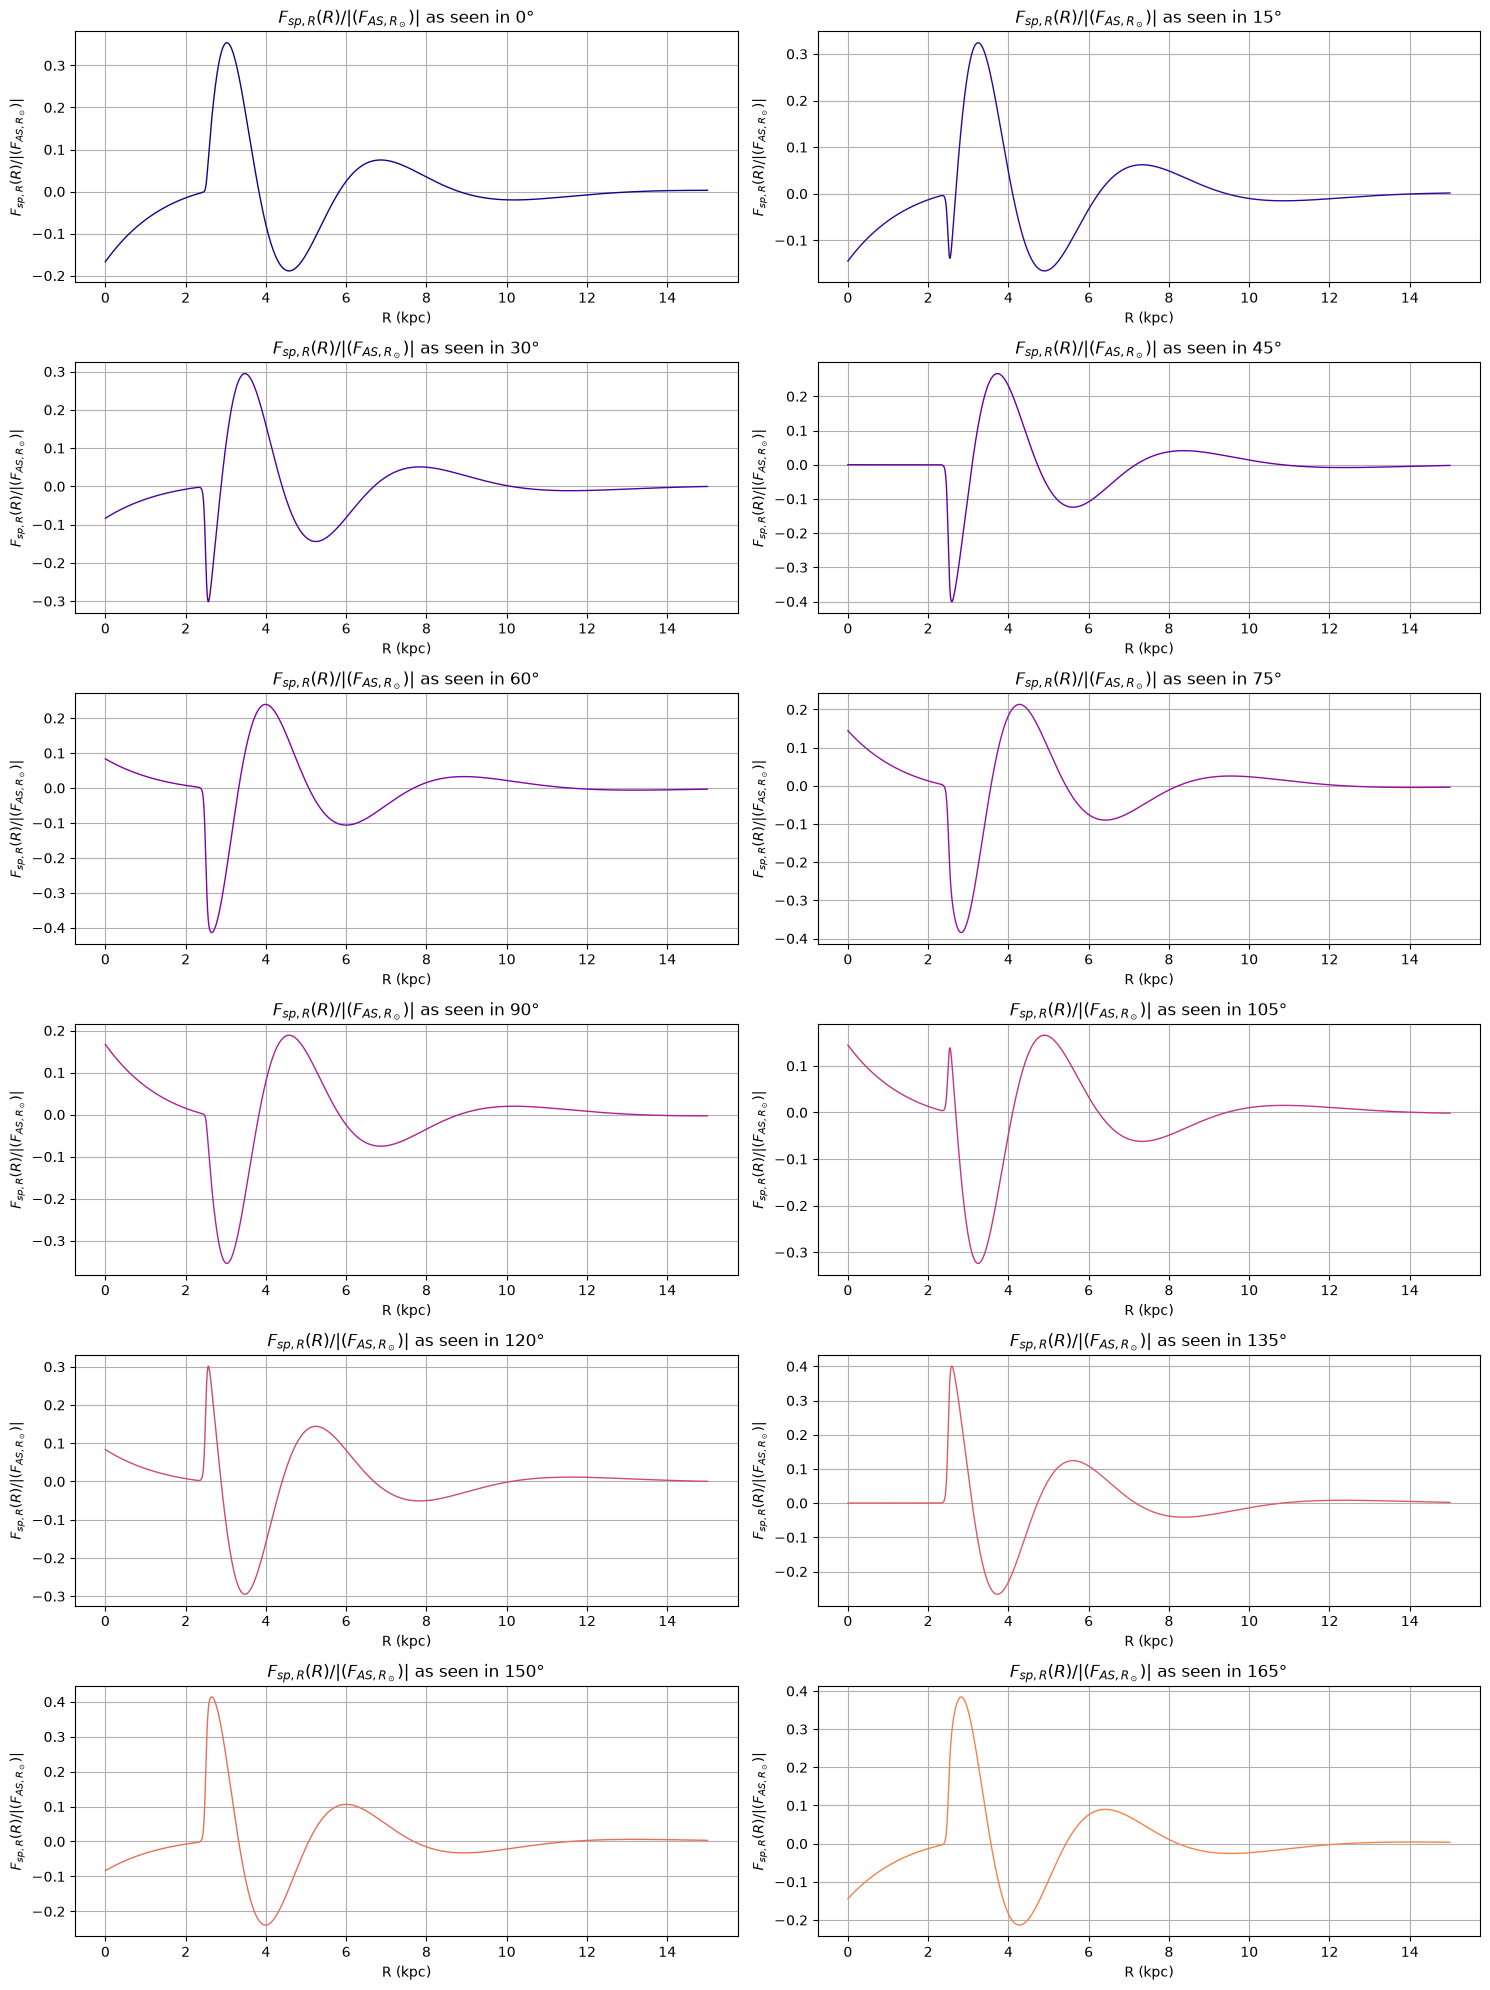

In [6]:
colors = plt.cm.plasma(np.linspace(0, 0.7, len(theta)))

fig, ax = plt.subplots(6, 2, figsize = (15, 20))

for i in range(6):
    ax[i, 0].plot(R, radial_forces[str(theta_[2*i])], lw = 1, color = colors[2*i])
    ax[i, 0].set_xlabel(r"R (kpc)")
    ax[i, 0].set_ylabel(r"$F_{sp, R}(R) / |(F_{AS, R_\odot})|$")
    ax[i, 0].set_title(r"$F_{sp, R}(R) / |(F_{AS, R_\odot})|$" + f" as seen in {15*2*i}°")
    ax[i, 0].grid()

    ax[i, 1].plot(R, radial_forces[str(theta_[2*i+1])], lw = 1, color = colors[2*i+1])
    ax[i, 1].set_xlabel(r"R (kpc)")
    ax[i, 1].set_ylabel(r"$F_{sp, R}(R) / |(F_{AS, R_\odot})|$")
    ax[i, 1].set_title(r"$F_{sp, R}(R) / |(F_{AS, R_\odot})|$" + f" as seen in {15*(2*i+1)}°")
    ax[i, 1].grid()
    
plt.tight_layout()
plt.show()